<a href="https://colab.research.google.com/github/Lekhana-Y/ML/blob/main/DT_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing Libraries

This code imports the required Python libraries for loading the dataset, splitting the data, creating the Decision Tree Regression model, calculating accuracy and confusion matrix, and displaying the tree.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import mean_squared_error

In [ ]:
df = pd.read_csv("house_price_regression_dataset.csv")
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Loading the Dataset

This code loads the house price CSV file and displays the first few rows of the dataset. It helps us check the available features and house prices.

Splitting the Dataset

The dataset is divided into training and testing data. 80% of the data is used for training the model and 20% is used for testing.

Separating Features and Target

Here, the House_Price column is taken as the target, and all the other columns are used as input features for prediction.

In [ ]:


X = df.drop("House_Price", axis=1)
y = df["House_Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 24084.455174223684
R2 Score: 0.9849578447417716


Price Categorization

This code divides the house prices into three categories: Low, Medium, and High. It converts the actual and predicted prices into these categories so that accuracy and the confusion matrix can be calculated.

In [ ]:
bins = [0, y.median()*0.75, y.median()*1.25, float("inf")]
labels = ["Low", "Medium", "High"]


Calculating Accuracy and Confusion Matrix

The predicted price categories are compared with the actual categories. Accuracy shows the percentage of correct predictions, and the confusion matrix shows correct and incorrect predictions for each category.

In [ ]:

y_test_class = pd.cut(y_test, bins=bins, labels=labels)
y_pred_class = pd.cut(y_pred, bins=bins, labels=labels)

accuracy = accuracy_score(y_test_class, y_pred_class)
cm = confusion_matrix(y_test_class, y_pred_class, labels=labels)

print("Accuracy:", accuracy)

Accuracy: 0.95


Confusion Matrix Output



The confusion matrix shows how many houses were correctly and incorrectly predicted as Low, Medium, or High price. The diagonal values represent the correct predictions.



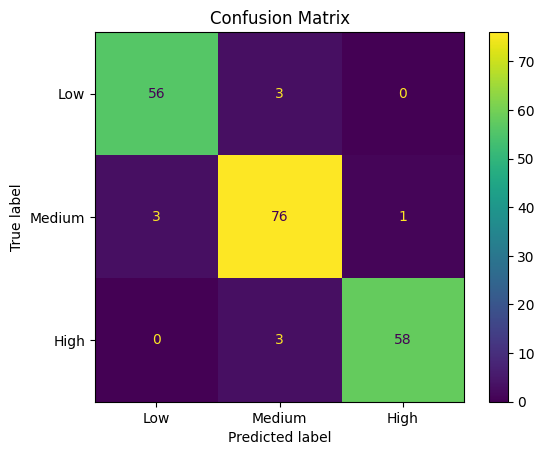

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.title("Confusion Matrix")
plt.show()


Calculate MSE

In [ ]:

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Squared Error: 969600136.0587759
Mean Absolute Error: 24084.455174223684
R2 Score: 0.9849578447417716


Decision Tree Visualization

This code displays the Decision Tree used for predicting house prices. Each box shows the feature and condition used to split the data. The tree makes decisions by following the True or False branches.

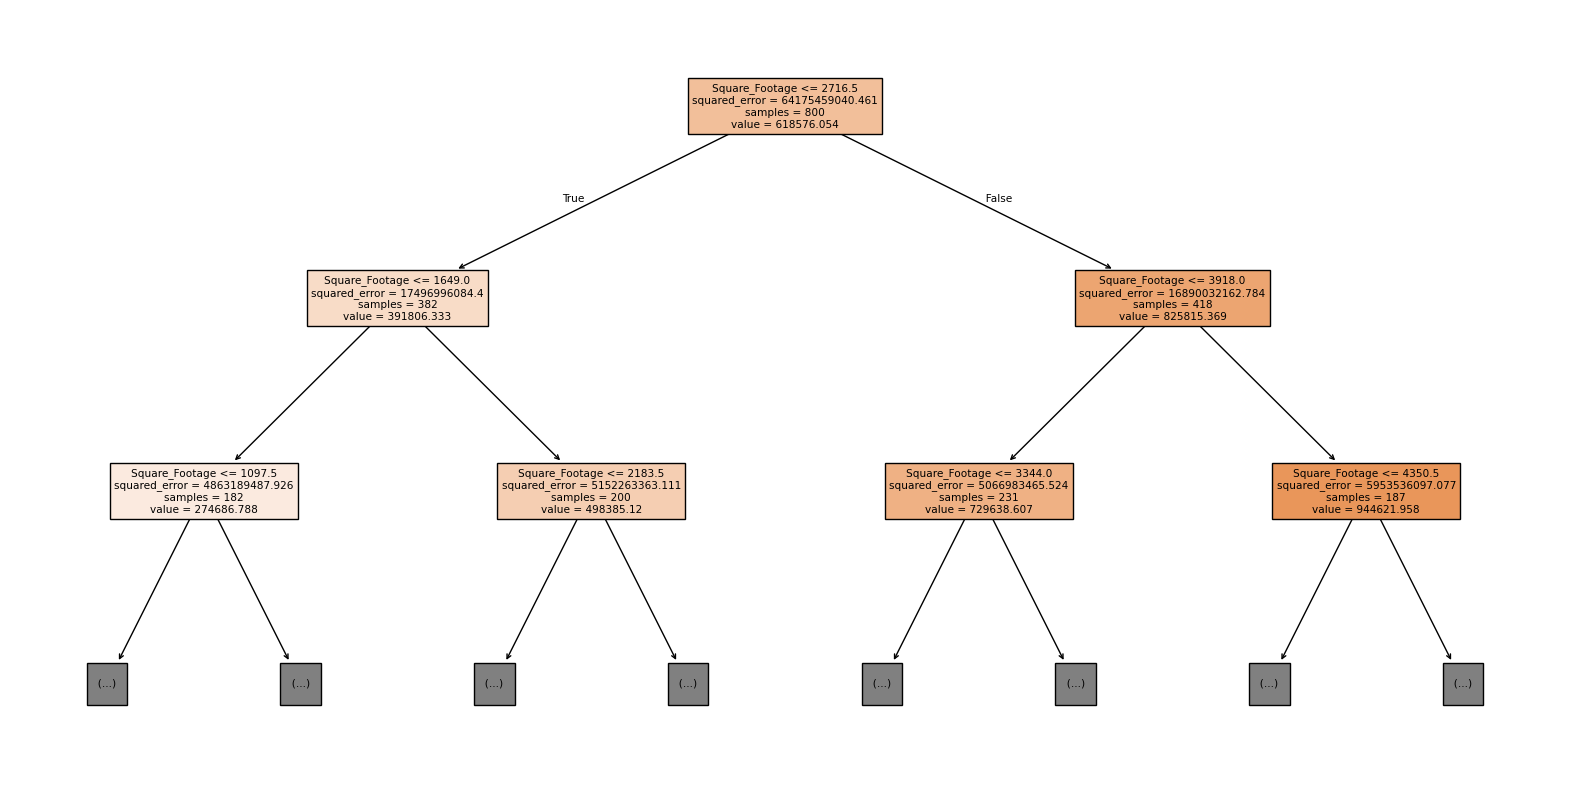

In [ ]:
plt.figure(figsize=(20,10))
plot_tree(model, feature_names=X.columns, filled=True, max_depth=2)
plt.show()